# Validación, limpieza y exploración ambiental
**La Araucanía · enero de 2014–diciembre de 2023 · frecuencia mensual**

Usamos exclusivamente las tablas de `datos_mensuales_2014_2023`. La referencia vial de 2019 se revisa por separado. Los archivos originales se conservan; las copias limpias y el informe se escriben en `limpios/`.

**Objetivo:** comprobar la calidad, describir el ciclo anual, identificar anomalías y comparar comunas. Esta exploración no es un modelo de riesgo ni establece causalidad.

Ejecutar con el intérprete `.venv` del proyecto. Dependencias en `requirements-analisis.txt`.

In [1]:
%matplotlib inline
from pathlib import Path
import json, hashlib, unicodedata, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from IPython.display import display, Markdown

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'datos_mensuales_2014_2023').is_dir())
DATA = ROOT / 'datos_mensuales_2014_2023'
OUTPUT = DATA / 'limpios'
EXPECTED_MONTHS = pd.date_range('2014-01-01', '2023-12-01', freq='MS')
MIN_COVERAGE = 80.0  # Criterio exploratorio configurable, no un estándar universal.
MONTH_LABELS = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
CORE = {
    'temperature_2m_c': ('Temperatura media', '°C', '#C74A3A'),
    'precipitation_mm': ('Precipitación mensual', 'mm/mes', '#277DA8'),
    'relative_humidity_2m_pct': ('Humedad relativa', '%', '#39836B'),
    'soil_moisture_0_10cm_kgm2': ('Humedad del suelo 0–10 cm', 'kg/m²', '#94713F'),
    'wind_speed_10m_ms': ('Viento a 10 m', 'm/s', '#7B60A8'),
    'aod_550': ('Aerosoles AOD 550 nm', 'adimensional', '#555F69'),
}
UNITS = {
    'temperature_2m_c': '°C', 'dewpoint_2m_c': '°C',
    'specific_humidity_2m_kgkg': 'kg/kg', 'wind_u_10m_ms': 'm/s',
    'wind_v_10m_ms': 'm/s', 'wind_speed_lowest_model_ms': 'm/s',
    'soil_moisture_0_10cm_kgm2': 'kg/m²', 'soil_temperature_0_10cm_c': '°C',
    'aod_550': 'adimensional', 'precipitation_mm': 'mm/mes',
    'temperature_monthly_max_c': '°C', 'relative_humidity_2m_pct': '%',
    'wind_speed_10m_ms': 'm/s', 'temperature_monthly_peak_area_mean_c': '°C',
}
SOIL = ['soil_moisture_0_10cm_kgm2', 'soil_temperature_0_10cm_c']
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 26)
print(f'Python {platform.python_version()} · pandas {pd.__version__} · numpy {np.__version__}')

Python 3.13.18 · pandas 3.1.1 · numpy 2.5.4


## 1. Carga y procedencia
Los códigos administrativos se leen como texto para conservar los ceros iniciales. Las fechas representan **meses**, no observaciones diarias. Las unidades se documentan explícitamente: no convertimos humedad específica en relativa, ni confundimos humedad y temperatura del suelo.

In [2]:
original_metadata = json.loads((DATA / 'metadatos.json').read_text(encoding='utf-8'))
raw_region = pd.read_csv(DATA / 'region_mensual.csv', dtype={'region_id': 'string'})
raw_communes = pd.read_csv(DATA / 'comunas_mensual.csv', dtype={'region_id': 'string', 'commune_id': 'string'})
raw_roads = pd.read_csv(DATA / 'infraestructura_vial_referencia_2019.csv', dtype={'region_id': 'string', 'commune_id': 'string'})
VARIABLES = list(original_metadata['variables'])
assert set(VARIABLES) == set(UNITS)
source_files = [DATA / name for name in ['region_mensual.csv', 'comunas_mensual.csv', 'infraestructura_vial_referencia_2019.csv', 'metadatos.json']]
source_hashes = {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}
checksum_checks = {name: source_hashes[name] == item['sha256'] for name, item in original_metadata['files'].items()}
assert all(checksum_checks.values()), 'El contenido original no coincide con sus checksums.'
display(pd.DataFrame([
    {'tabla': 'Región mensual', 'filas': len(raw_region), 'columnas': raw_region.shape[1]},
    {'tabla': 'Comunas mensuales', 'filas': len(raw_communes), 'columnas': raw_communes.shape[1]},
    {'tabla': 'Referencia vial 2019', 'filas': len(raw_roads), 'columnas': raw_roads.shape[1]},
]))
display(pd.DataFrame({'variable': VARIABLES, 'unidad_validada': [UNITS[v] for v in VARIABLES], 'unidad_metadato_original': [original_metadata['variables'][v].get('unit') for v in VARIABLES]}))

,tabla,filas,columnas
0,Región mensual,120,22
1,Comunas mensuales,3840,23
2,Referencia vial 2019,33,7


,variable,unidad_validada,unidad_metadato_original
0,temperature_2m_c,°C,?C
1,dewpoint_2m_c,°C,?C
2,specific_humidity_2m_kgkg,kg/kg,kg/kg
3,wind_u_10m_ms,m/s,m/s
4,wind_v_10m_ms,m/s,m/s
5,wind_speed_lowest_model_ms,m/s,m/s
6,soil_moisture_0_10cm_kgm2,kg/m²,kg/m?
7,soil_temperature_0_10cm_c,°C,?C
8,aod_550,adimensional,1
9,precipitation_mm,mm/mes,mm/month


## 2. Validación previa a la limpieza
Comprobamos claves, calendario completo, tipos numéricos, faltantes y rangos básicos. Las componentes U/V pueden ser negativas; las temperaturas negativas también son válidas. Los extremos climáticos no se eliminan automáticamente.

`commune_id` vacío en la fila vial regional es un valor estructural esperado: esa fila corresponde a toda la región.

In [3]:
checks = []
def record_check(name, condition, detail=''):
    checks.append({'control': name, 'resultado': 'OK' if bool(condition) else 'REVISAR', 'detalle': str(detail)})

def audit_monthly(df, label, communal=False):
    parsed = pd.to_datetime(df['month'], format='%Y-%m', errors='coerce')
    keys = ['month', 'commune_id'] if communal else ['month', 'region_id']
    record_check(f'{label}: fechas válidas', parsed.notna().all())
    record_check(f'{label}: claves completas', df[keys].notna().all().all())
    record_check(f'{label}: sin claves duplicadas', not df.duplicated(keys).any())
    record_check(f'{label}: calendario 2014–2023', set(parsed) == set(EXPECTED_MONTHS))
    record_check(f'{label}: región 09', df.region_id.eq('09').all())
    values = df[VARIABLES].apply(pd.to_numeric, errors='coerce')
    record_check(f'{label}: variables numéricas finitas', np.isfinite(values.to_numpy()).all())
    record_check(f'{label}: sin faltantes en mediciones', values.notna().all().all())
    bounds = {'precipitation_mm': (0, np.inf), 'relative_humidity_2m_pct': (0, 100),
              'specific_humidity_2m_kgkg': (0, 1), 'wind_speed_10m_ms': (0, np.inf),
              'wind_speed_lowest_model_ms': (0, np.inf), 'aod_550': (0, np.inf),
              'soil_moisture_0_10cm_kgm2': (0, 100)}
    for variable, (low, high) in bounds.items():
        record_check(f'{label}: rango {variable}', values[variable].between(low, high).all())
    record_check(f'{label}: rocío ≤ temperatura media', (values.dewpoint_2m_c <= values.temperature_2m_c + .01).all())
    record_check(f'{label}: máxima de malla ≥ media de máximas', (values.temperature_monthly_max_c + .01 >= values.temperature_monthly_peak_area_mean_c).all())
    coverage = df.filter(like='_valid_area_pct')
    record_check(f'{label}: cobertura espacial válida', coverage.notna().all().all() and coverage.ge(0).all().all() and coverage.le(100).all().all())
    if communal:
        counts = df.groupby('commune_id').size()
        record_check('32 comunas y 120 meses por comuna', len(counts) == 32 and counts.eq(120).all())
        record_check('Códigos comunales válidos', df.commune_id.str.fullmatch(r'09\d{3}').all())
        record_check('Un nombre por código comunal', df.groupby('commune_id').commune_name.nunique().eq(1).all())

audit_monthly(raw_region, 'Región')
audit_monthly(raw_communes, 'Comunas', communal=True)
record_check('Región: 120 filas', len(raw_region) == 120)
record_check('Comunas: 3.840 filas', len(raw_communes) == 3840)
record_check('Vialidad: una región y 32 comunas', len(raw_roads) == 33 and raw_roads.commune_id.isna().sum() == 1 and raw_roads.commune_id.nunique() == 32)
record_check('Vialidad: referencia única 2019', raw_roads.reference_year.eq(2019).all())
record_check('Vialidad: longitudes válidas', raw_roads.road_length_km.notna().all() and raw_roads.road_length_km.ge(0).all())
regional_road = raw_roads.loc[raw_roads.commune_id.isna(), 'road_length_km'].iloc[0]
communal_road = raw_roads.loc[raw_roads.commune_id.notna(), 'road_length_km'].sum()
record_check('Vialidad: suma comunal ≈ total regional', np.isclose(regional_road, communal_road, atol=.05, rtol=1e-5))
audit = pd.DataFrame(checks)
display(audit)
assert audit.resultado.eq('OK').all(), 'Revisar los controles antes de continuar.'

,control,resultado,detalle
0,Región: fechas válidas,OK,
1,Región: claves completas,OK,
2,Región: sin claves duplicadas,OK,
3,Región: calendario 2014–2023,OK,
4,Región: región 09,OK,
5,Región: variables numéricas finitas,OK,
6,Región: sin faltantes en mediciones,OK,
7,Región: rango precipitation_mm,OK,
8,Región: rango relative_humidity_2m_pct,OK,
9,Región: rango specific_humidity_2m_kgkg,OK,


## 3. Limpieza trazable y cobertura
Se corrigen únicamente etiquetas y unidades identificables. No se vuelve a convertir Kelvin a Celsius: los campos `_c` ya están expresados en Celsius.

Se añade `soil_coverage_ok` con un umbral exploratorio del 80 %. Los valores originales se conservan en las tablas limpias; para comparar comunas se enmascaran **solo las variables de suelo** cuando la cobertura es insuficiente. No se rellenan ni recortan valores extremos.

In [4]:
region = raw_region.copy(deep=True)
communes = raw_communes.copy(deep=True)
roads = raw_roads.copy(deep=True)
cleaning_log = []

def normalize_text(series):
    return series.map(lambda v: unicodedata.normalize('NFC', v).strip() if isinstance(v, str) else v)

for frame in [region, communes, roads]:
    for column in frame.select_dtypes(include=['string', 'object']).columns:
        frame[column] = normalize_text(frame[column])
    frame['region_id'] = frame.region_id.astype('string').str.zfill(2)
    if 'commune_id' in frame:
        frame['commune_id'] = frame.commune_id.astype('string').str.zfill(5)

for frame, column, label in [(region, 'region_name', 'región mensual'), (roads, 'name', 'referencia vial')]:
    bad = frame[column].eq('La Araucan?a')
    if bad.any():
        frame.loc[bad, column] = 'La Araucanía'
        cleaning_log.append({'tabla': label, 'campo': column, 'antes': 'La Araucan?a', 'después': 'La Araucanía', 'filas': int(bad.sum())})

for variable, unit in UNITS.items():
    previous = original_metadata['variables'][variable].get('unit')
    if previous != unit:
        cleaning_log.append({'tabla': 'metadatos', 'campo': variable, 'antes': previous, 'después': unit, 'filas': None})

for frame in [region, communes]:
    frame['month'] = pd.to_datetime(frame.month, format='%Y-%m')
    frame[VARIABLES] = frame[VARIABLES].apply(pd.to_numeric, errors='raise')
    frame['soil_coverage_ok'] = frame.suelo_mensual_valid_area_pct.ge(MIN_COVERAGE)
region = region.sort_values('month').reset_index(drop=True)
communes = communes.sort_values(['month', 'commune_id']).reset_index(drop=True)
roads['geography_level'] = np.where(roads.commune_id.isna(), 'region', 'commune')

assert np.array_equal(region[VARIABLES].to_numpy(), raw_region.sort_values('month')[VARIABLES].to_numpy())
assert np.array_equal(communes[VARIABLES].to_numpy(), raw_communes.sort_values(['month', 'commune_id'])[VARIABLES].to_numpy())
display(pd.DataFrame(cleaning_log))
coverage_by_commune = communes.groupby(['commune_id', 'commune_name'], observed=True).agg(
    cobertura_suelo_min_pct=('suelo_mensual_valid_area_pct', 'min'),
    meses_con_cobertura_insuficiente=('soil_coverage_ok', lambda s: int((~s).sum())),
).sort_values('cobertura_suelo_min_pct')
display(coverage_by_commune.head(8))
display(Markdown(f'**Filas comunales con suelo bajo el umbral:** {(~communes.soil_coverage_ok).sum():,}. Esto indica cobertura parcial del producto, no mediciones necesariamente erróneas.'))

,tabla,campo,antes,después,filas
0,región mensual,region_name,La Araucan?a,La Araucanía,120.0
1,referencia vial,name,La Araucan?a,La Araucanía,1.0
2,metadatos,temperature_2m_c,?C,°C,NaN
3,metadatos,dewpoint_2m_c,?C,°C,NaN
4,metadatos,soil_moisture_0_10cm_kgm2,kg/m?,kg/m²,NaN
5,metadatos,soil_temperature_0_10cm_c,?C,°C,NaN
6,metadatos,aod_550,1,adimensional,NaN
7,metadatos,precipitation_mm,mm/month,mm/mes,NaN
8,metadatos,temperature_monthly_max_c,?C,°C,NaN
9,metadatos,temperature_monthly_peak_area_mean_c,?C,°C,NaN


,,cobertura_suelo_min_pct,meses_con_cobertura_insuficiente
commune_id,commune_name,,
09116,Saavedra,36.49,120
09117,Teodoro Schmidt,84.58,0
09102,Carahue,99.06,0
09103,Cunco,100.00,0
09105,Freire,100.00,0
09106,Galvarino,100.00,0
09107,Gorbea,100.00,0
09101,Temuco,100.00,0


**Filas comunales con suelo bajo el umbral:** 120. Esto indica cobertura parcial del producto, no mediciones necesariamente erróneas.

In [5]:
# Las copias para EDA enmascaran solamente suelo con cobertura insuficiente.
regional_eda = region.set_index('month').copy()
communal_eda = communes.copy()
regional_eda.loc[~regional_eda.soil_coverage_ok, SOIL] = np.nan
communal_eda.loc[~communal_eda.soil_coverage_ok, SOIL] = np.nan

summary = regional_eda[list(CORE)].describe(percentiles=[.25, .5, .75]).T
summary.insert(0, 'unidad', [UNITS[v] for v in summary.index])
display(summary.round(3))

# Señales IQR calculadas dentro de cada mes calendario: sirven para revisión,
# nunca para borrar automáticamente meses secos, lluviosos o cálidos.
flags = []
for variable in CORE:
    series = regional_eda[variable]
    q1 = series.groupby(series.index.month).transform(lambda s: s.quantile(.25))
    q3 = series.groupby(series.index.month).transform(lambda s: s.quantile(.75))
    iqr = q3 - q1
    flagged = (iqr > 0) & ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr))
    for date in series.index[flagged]:
        flags.append({'month': date.strftime('%Y-%m'), 'variable': variable, 'valor': float(series.loc[date]), 'criterio': 'IQR dentro del mes calendario; revisar, no eliminar'})
extremes = pd.DataFrame(flags, columns=['month', 'variable', 'valor', 'criterio'])
display(extremes.head(12))
print(f'{len(extremes)} señales exploratorias de extremos; ninguna observación eliminada.')

,unidad,count,mean,std,min,25%,50%,75%,max
temperature_2m_c,°C,120.0,10.262,4.173,3.967,6.453,9.548,13.965,17.467
precipitation_mm,mm/mes,120.0,102.285,87.910,4.489,29.551,67.630,162.016,339.737
relative_humidity_2m_pct,%,120.0,75.856,9.884,50.965,69.005,77.813,83.588,91.578
soil_moisture_0_10cm_kgm2,kg/m²,120.0,26.292,7.028,13.234,19.202,27.206,32.486,37.436
wind_speed_10m_ms,m/s,120.0,2.749,0.255,2.187,2.554,2.754,2.916,3.317
aod_550,adimensional,120.0,0.071,0.019,0.040,0.056,0.069,0.081,0.163


,month,variable,valor,criterio
0,2016-05,temperature_2m_c,9.217,"IQR dentro del mes calendario; revisar, no eli..."
1,2016-09,temperature_2m_c,8.634,"IQR dentro del mes calendario; revisar, no eli..."
2,2017-05,temperature_2m_c,7.047,"IQR dentro del mes calendario; revisar, no eli..."
3,2017-08,temperature_2m_c,4.571,"IQR dentro del mes calendario; revisar, no eli..."
4,2019-01,temperature_2m_c,14.558,"IQR dentro del mes calendario; revisar, no eli..."
5,2022-05,temperature_2m_c,6.469,"IQR dentro del mes calendario; revisar, no eli..."
6,2022-11,temperature_2m_c,15.360,"IQR dentro del mes calendario; revisar, no eli..."
7,2023-01,temperature_2m_c,17.080,"IQR dentro del mes calendario; revisar, no eli..."
8,2023-06,temperature_2m_c,6.569,"IQR dentro del mes calendario; revisar, no eli..."
9,2023-07,temperature_2m_c,5.734,"IQR dentro del mes calendario; revisar, no eli..."


42 señales exploratorias de extremos; ninguna observación eliminada.


## 4. Evolución mensual regional
Seis indicadores principales en sus unidades originales, en paneles separados. Los extremos de temperatura de la malla y las componentes U/V se mantienen en las tablas, pero no se mezclan con temperatura media y velocidad escalar.

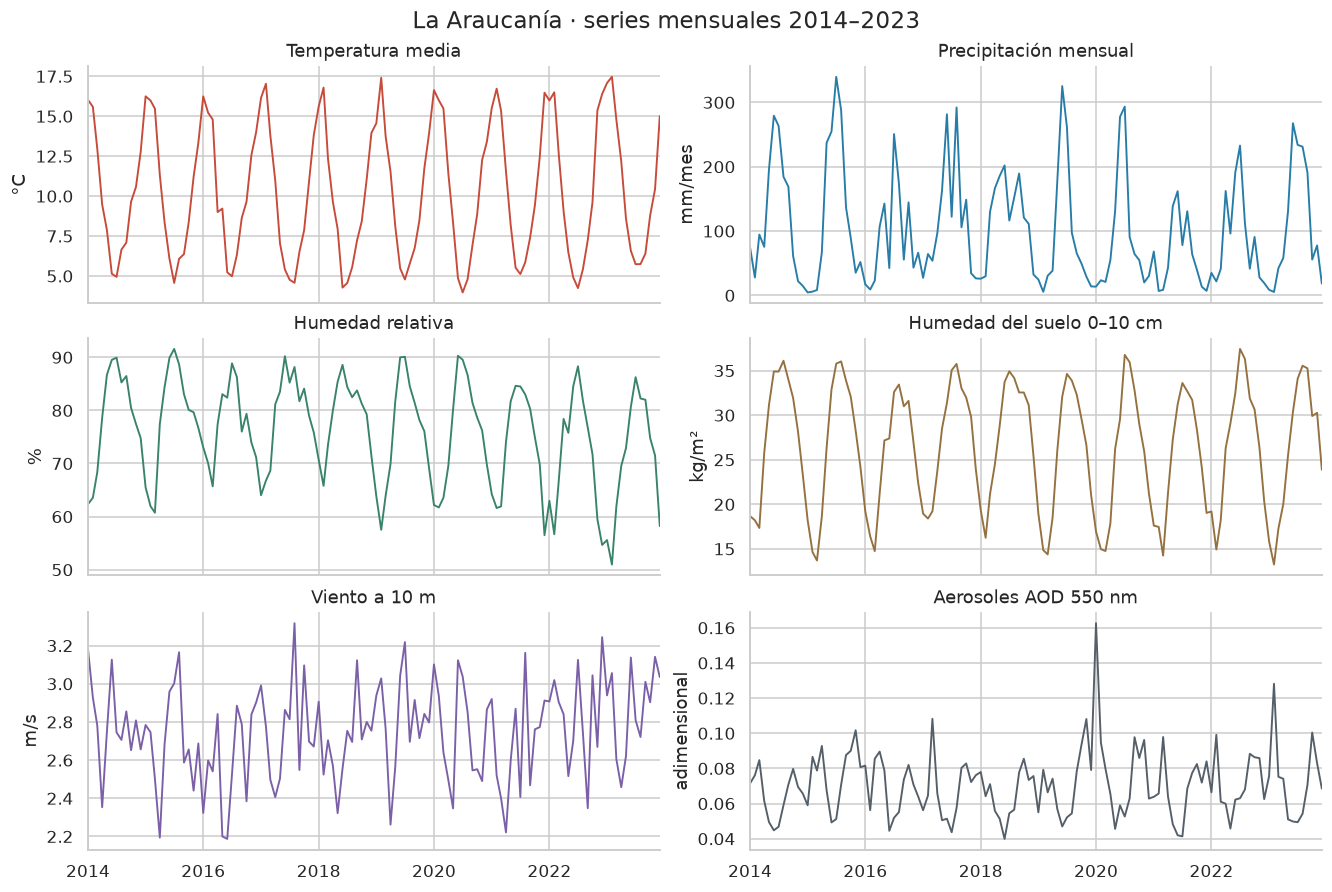

In [6]:
fig, axes = plt.subplots(3, 2, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, (variable, (title, unit, color)) in zip(axes.flat, CORE.items()):
    ax.plot(regional_eda.index, regional_eda[variable], color=color, linewidth=1.25)
    ax.set(title=title, ylabel=unit, xlim=(EXPECTED_MONTHS.min(), EXPECTED_MONTHS.max()))
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
fig.suptitle('La Araucanía · series mensuales 2014–2023', fontsize=15)
plt.show()

## 5. Ciclo anual y variabilidad entre años
Cada caja reúne diez observaciones del mismo mes calendario. La línea negra indica su promedio dentro de 2014–2023. Esta referencia describe nuestro período de estudio.

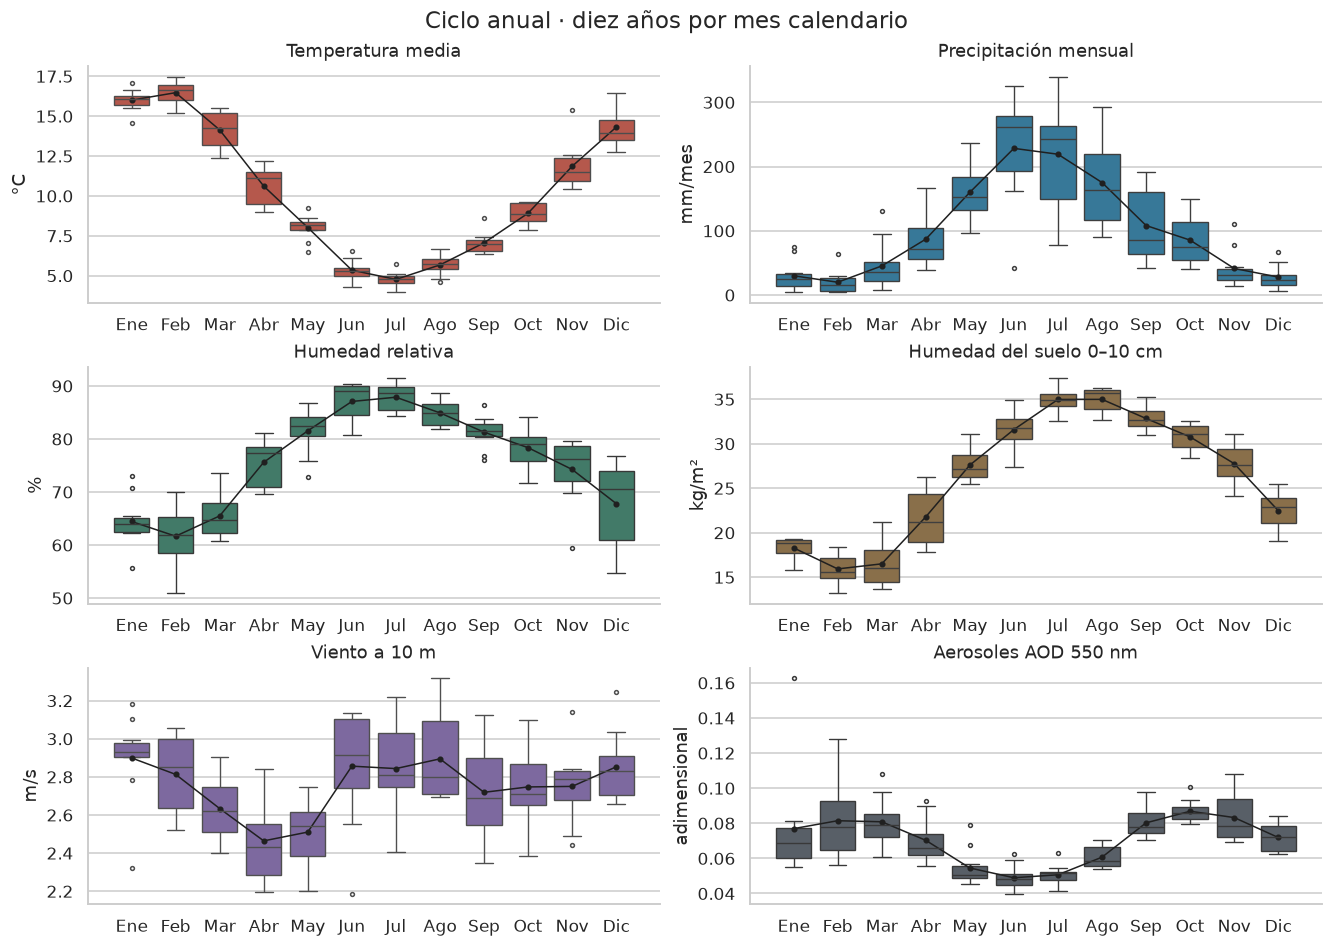

In [7]:
seasonal = regional_eda[list(CORE)].copy()
seasonal['calendar_month'] = seasonal.index.month
fig, axes = plt.subplots(3, 2, figsize=(12, 8.5), constrained_layout=True)
for ax, (variable, (title, unit, color)) in zip(axes.flat, CORE.items()):
    sns.boxplot(data=seasonal, x='calendar_month', y=variable, order=list(range(1, 13)), color=color, fliersize=2.5, linewidth=.9, ax=ax)
    averages = seasonal.groupby('calendar_month')[variable].mean().reindex(range(1, 13))
    ax.plot(np.arange(12), averages, '-o', color='#202020', linewidth=1, markersize=3)
    ax.set_xticks(range(12), MONTH_LABELS)
    ax.set(title=title, xlabel='', ylabel=unit)
fig.suptitle('Ciclo anual · diez años por mes calendario', fontsize=15)
plt.show()

## 6. Anomalías: separar la estación del año
Anomalía = valor observado − promedio del mismo mes durante 2014–2023. Así, enero se compara con otros eneros. Se usan diferencias en °C y mm, no una mezcla de unidades ni una conversión de meses a días.

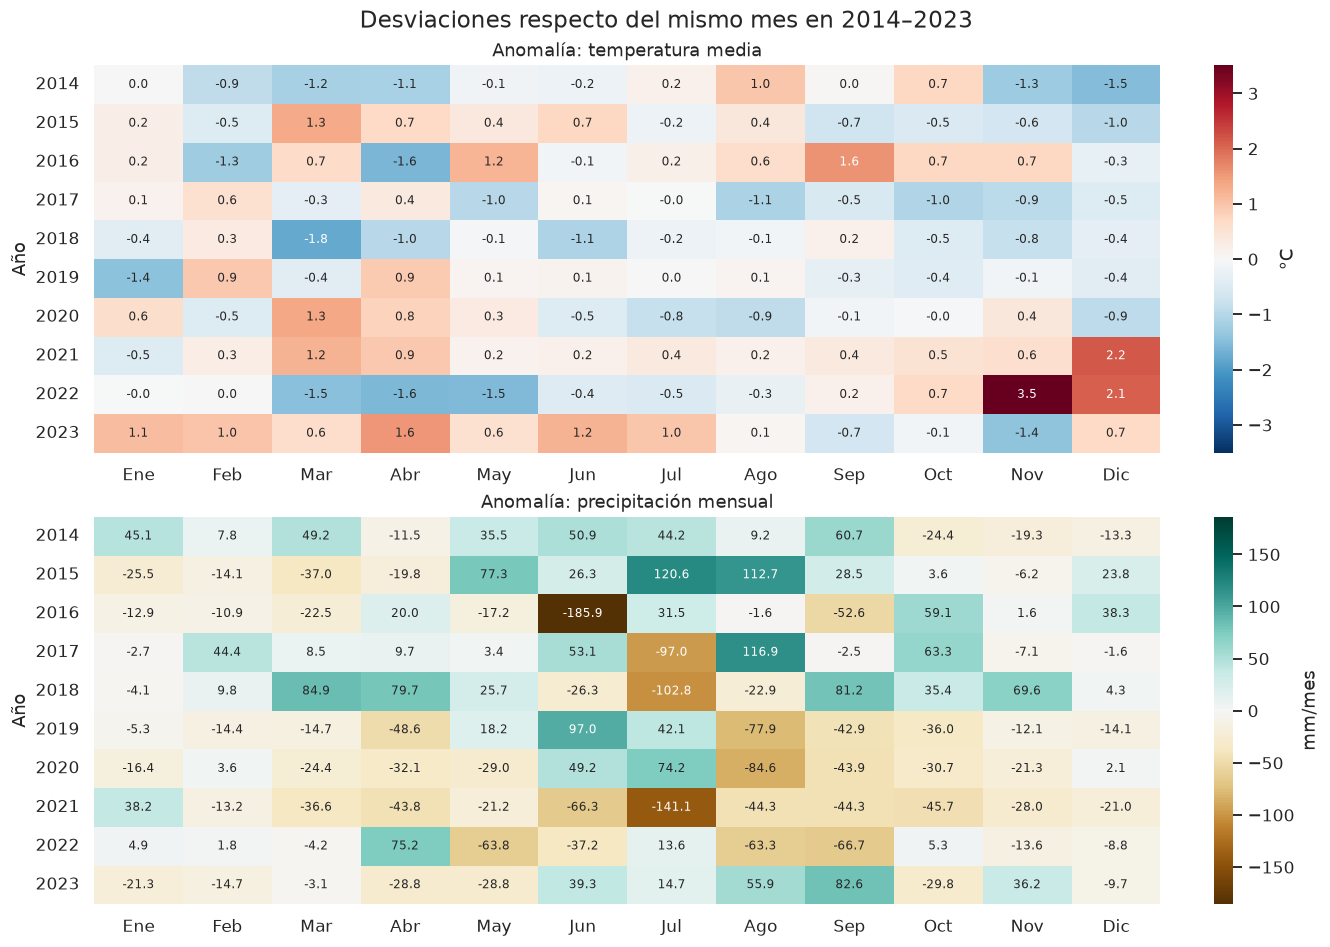

In [8]:
anomalies = regional_eda[list(CORE)] - regional_eda[list(CORE)].groupby(regional_eda.index.month).transform('mean')
assert np.allclose(anomalies.groupby(anomalies.index.month).mean(), 0, atol=1e-8)
fig, axes = plt.subplots(2, 1, figsize=(12, 8.5), constrained_layout=True)
for ax, variable, palette in zip(axes, ['temperature_2m_c', 'precipitation_mm'], ['RdBu_r', 'BrBG']):
    data = anomalies[[variable]].assign(year=anomalies.index.year, month=anomalies.index.month)
    matrix = data.pivot(index='year', columns='month', values=variable)
    limit = max(float(np.nanmax(np.abs(matrix))), .01)
    sns.heatmap(matrix, ax=ax, cmap=palette, center=0, vmin=-limit, vmax=limit, annot=True, fmt='.1f', annot_kws={'fontsize': 8}, cbar_kws={'label': UNITS[variable]})
    ax.set_xticklabels(MONTH_LABELS, rotation=0)
    ax.set(title=f'Anomalía: {CORE[variable][0].lower()}', xlabel='', ylabel='Año')
fig.suptitle('Desviaciones respecto del mismo mes en 2014–2023', fontsize=15)
plt.show()

## 7. Comparación entre comunas
Promedios del período, calculados con las observaciones que cumplen cobertura. La matriz estandariza **cada variable entre comunas** para comparar perfiles sin mezclar unidades. El gris identifica suelo excluido por cobertura insuficiente.

Las comunas pueden compartir píxeles nativos. Estas diferencias no implican mediciones independientes a escala local ni permiten tratar las 3.840 filas como muestras espaciales independientes.

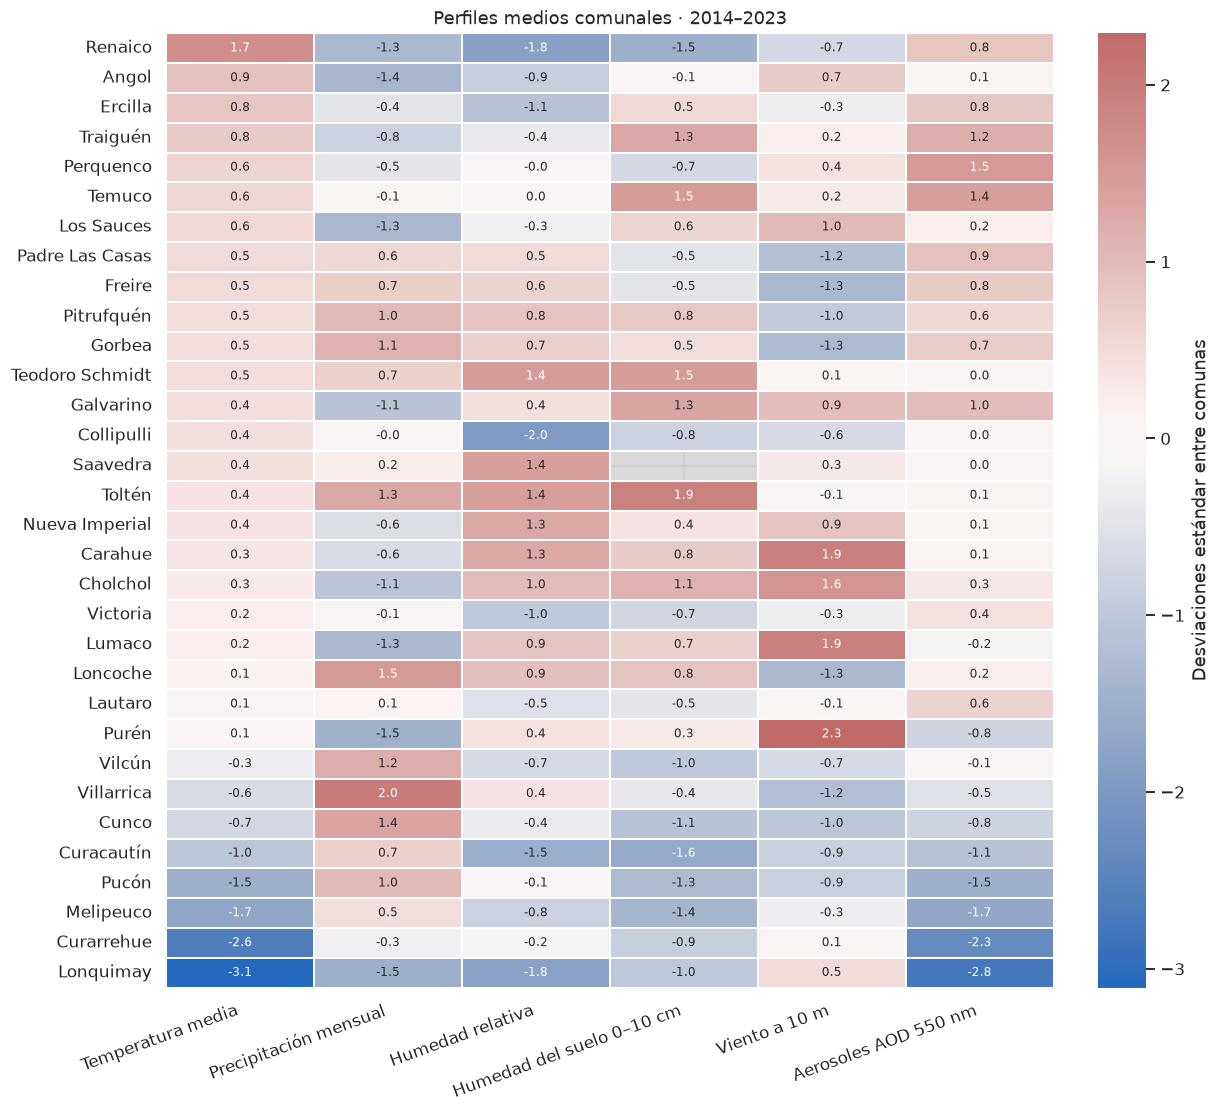

,temperature_2m_c,precipitation_mm,relative_humidity_2m_pct,soil_moisture_0_10cm_kgm2,wind_speed_10m_ms,aod_550
commune_name,,,,,,
Renaico,13.273,79.886,70.543,22.546,2.329,0.082
Angol,12.183,79.401,73.866,26.762,3.264,0.075
Ercilla,12.081,94.736,72.987,28.736,2.584,0.082
Traiguén,11.979,88.548,75.571,30.918,2.910,0.086
Perquenco,11.744,94.553,76.688,24.966,3.048,0.088
Temuco,11.730,101.268,76.914,31.501,2.940,0.088
Los Sauces,11.694,79.917,75.982,28.898,3.425,0.077
Padre Las Casas,11.621,112.017,78.478,25.708,2.008,0.083


In [9]:
profiles = communal_eda.groupby('commune_name', observed=True)[list(CORE)].mean()
profiles = profiles.sort_values('temperature_2m_c', ascending=False)
standardized = (profiles - profiles.mean()) / profiles.std(ddof=0).replace(0, np.nan)
palette = sns.color_palette('vlag', as_cmap=True)
fig, ax = plt.subplots(figsize=(11, 10), constrained_layout=True)
ax.set_facecolor('#D9D9D9')
sns.heatmap(standardized, cmap=palette, center=0, annot=True, fmt='.1f', annot_kws={'fontsize': 8}, linewidths=.25, ax=ax, cbar_kws={'label': 'Desviaciones estándar entre comunas'})
ax.set_xticklabels([CORE[v][0] for v in standardized.columns], rotation=20, ha='right')
ax.set(title='Perfiles medios comunales · 2014–2023', xlabel='', ylabel='')
plt.show()
display(profiles.round(3).head(8))

## 8. Relaciones exploratorias
Se compara la correlación de Spearman de las series mensuales con la de sus anomalías. Se calcula como correlación de rangos promedio, conservando los empates.

Son asociaciones descriptivas: hay autocorrelación temporal y fuentes de reanálisis compartidas. No se interpretan como causalidad, significación estadística independiente ni capacidad predictiva.

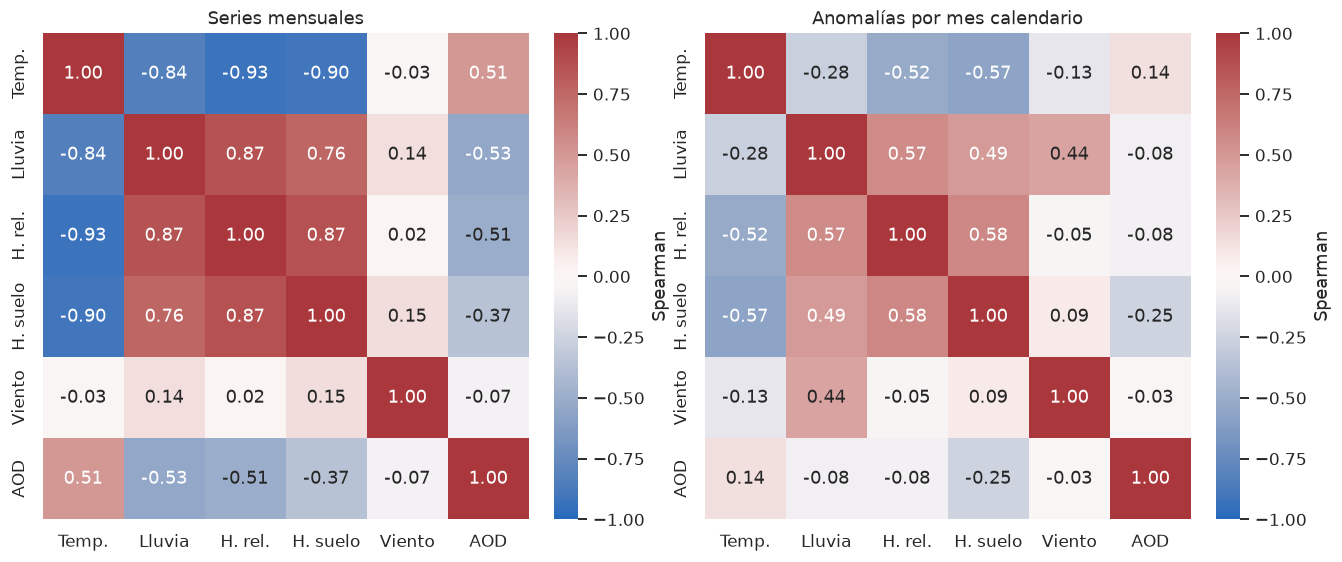

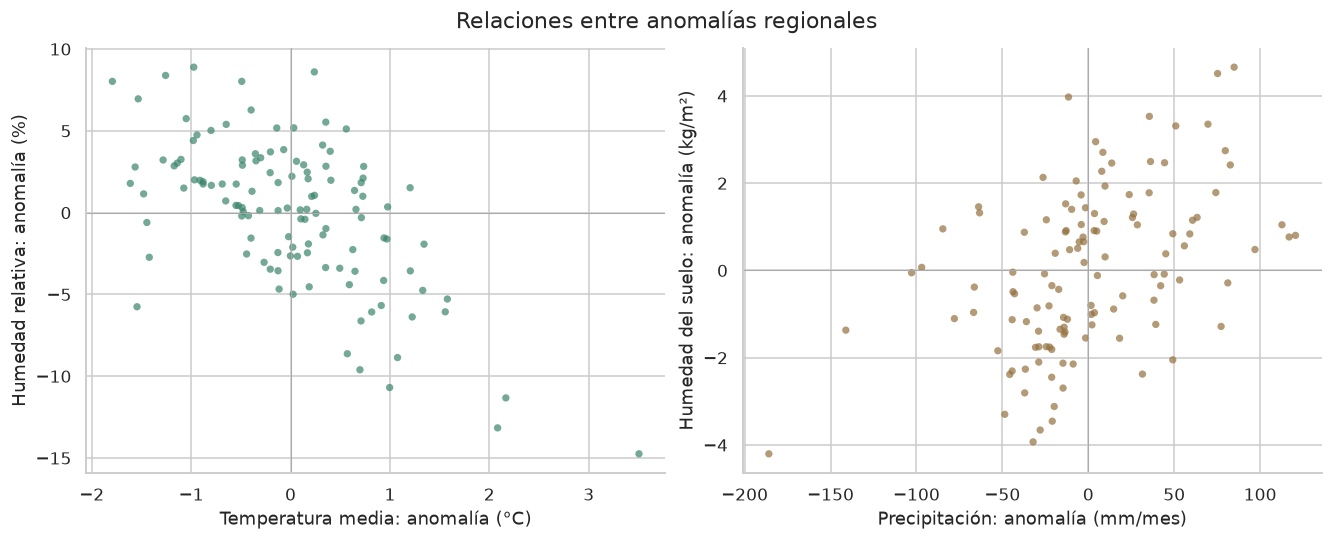

In [10]:
raw_corr = regional_eda[list(CORE)].rank().corr()
anomaly_corr = anomalies.rank().corr()
short_labels = ['Temp.', 'Lluvia', 'H. rel.', 'H. suelo', 'Viento', 'AOD']
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, matrix, title in zip(axes, [raw_corr, anomaly_corr], ['Series mensuales', 'Anomalías por mes calendario']):
    sns.heatmap(matrix, ax=ax, cmap='vlag', vmin=-1, vmax=1, center=0, square=True, annot=True, fmt='.2f', xticklabels=short_labels, yticklabels=short_labels, cbar_kws={'label': 'Spearman'})
    ax.set_title(title)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), constrained_layout=True)
for ax, x, y in [(axes[0], 'temperature_2m_c', 'relative_humidity_2m_pct'), (axes[1], 'precipitation_mm', 'soil_moisture_0_10cm_kgm2')]:
    ax.scatter(anomalies[x], anomalies[y], s=23, color=CORE[y][2], alpha=.7, edgecolors='none')
    ax.axhline(0, color='#AAAAAA', linewidth=.7)
    ax.axvline(0, color='#AAAAAA', linewidth=.7)
    short_names = {'temperature_2m_c': 'Temperatura media', 'relative_humidity_2m_pct': 'Humedad relativa', 'precipitation_mm': 'Precipitación', 'soil_moisture_0_10cm_kgm2': 'Humedad del suelo'}
    ax.set(xlabel=f'{short_names[x]}: anomalía ({UNITS[x]})', ylabel=f'{short_names[y]}: anomalía ({UNITS[y]})')
fig.suptitle('Relaciones entre anomalías regionales')
plt.show()

## 9. Hallazgos preliminares y próximos pasos
Los siguientes resúmenes se calculan desde las tablas; no se escriben conclusiones numéricas fijas. La referencia vial de 2019 se conserva separada y no se replica como una observación para cada mes.

El repositorio también contiene CONAF. Antes de cruzarlo con meteorología, se debe verificar el año calendario frente a la temporada: el archivo regional es mensual y el comunal está organizado por temporadas. Esos registros no se mezclan todavía con esta base.

In [11]:
annual = regional_eda.groupby(regional_eda.index.year).agg(
    temperature_mean_c=('temperature_2m_c', 'mean'),
    precipitation_total_mm=('precipitation_mm', 'sum'),
)
warmest_year = int(annual.temperature_mean_c.idxmax())
driest_year = int(annual.precipitation_total_mm.idxmin())
soil_low = coverage_by_commune.query('meses_con_cobertura_insuficiente > 0')
upper_pairs = anomaly_corr.where(np.triu(np.ones(anomaly_corr.shape), k=1).astype(bool)).stack()
strongest_pair = upper_pairs.abs().idxmax()
strongest_value = float(upper_pairs.loc[strongest_pair])
findings = {
    'warmest_year_in_this_period': warmest_year,
    'lowest_precipitation_year_in_this_period': driest_year,
    'strongest_anomaly_spearman_pair': list(strongest_pair),
    'strongest_anomaly_spearman_value': strongest_value,
}
display(annual.round(2))
display(Markdown(
    f'- Año con mayor temperatura media regional en esta ventana: **{warmest_year}**.\n'
    f'- Año con menor precipitación acumulada regional: **{driest_year}**.\n'
    f'- Comunas con cobertura de suelo inferior al {MIN_COVERAGE:g} %: **{len(soil_low)}**.\n'
    f'- Asociación más fuerte entre anomalías: **{CORE[strongest_pair[0]][0]} / {CORE[strongest_pair[1]][0]}**, Spearman **{strongest_value:.2f}**.\n'
    '- Los extremos se mantienen. Los diez años describen este período y no bastan por sí solos para atribuir cambios climáticos.'
))
display(roads[['geography_level', 'commune_id', 'name', 'reference_year', 'road_length_km']].head())

,temperature_mean_c,precipitation_total_mm
month,,
2014,9.89,1461.48
2015,10.28,1517.70
2016,10.49,1074.36
2017,9.90,1415.89
2018,9.78,1461.80
2019,10.19,1118.48
2020,10.25,1073.96
2021,10.79,760.01
2022,10.32,1070.56


- Año con mayor temperatura media regional en esta ventana: **2021**.
- Año con menor precipitación acumulada regional: **2021**.
- Comunas con cobertura de suelo inferior al 80 %: **1**.
- Asociación más fuerte entre anomalías: **Humedad relativa / Humedad del suelo 0–10 cm**, Spearman **0.58**.
- Los extremos se mantienen. Los diez años describen este período y no bastan por sí solos para atribuir cambios climáticos.

,geography_level,commune_id,name,reference_year,road_length_km
0,region,<NA>,La Araucanía,2019,13981.362
1,commune,09101,Temuco,2019,1022.347
2,commune,09102,Carahue,2019,550.867
3,commune,09103,Cunco,2019,545.301
4,commune,09104,Curarrehue,2019,226.944


## 10. Exportación y comprobación de los originales
Se guardan tres CSV limpios y un reporte JSON, con códigos como texto, unidades corregidas, fuentes verificadas y decisiones de limpieza. `soil_coverage_ok` permite aplicar otros umbrales posteriormente. Las mediciones originales se conservan, incluso las marcadas por baja cobertura.

In [12]:
OUTPUT.mkdir(exist_ok=True)
region.to_csv(OUTPUT / 'region_mensual_limpio.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m')
communes.to_csv(OUTPUT / 'comunas_mensual_limpio.csv', index=False, encoding='utf-8-sig', date_format='%Y-%m')
roads.to_csv(OUTPUT / 'infraestructura_vial_limpia.csv', index=False, encoding='utf-8-sig')

report = {
    'scope': {'start': '2014-01', 'end': '2023-12', 'months': 120, 'communes': 32},
    'source_sha256': source_hashes,
    'all_checks_passed': bool(audit.resultado.eq('OK').all()),
    'checks': checks,
    'cleaning_log': cleaning_log,
    'units': UNITS,
    'measurement_values_changed': 0,
    'rows_removed': 0,
    'values_imputed': 0,
    'soil_coverage_threshold_pct': MIN_COVERAGE,
    'soil_rows_flagged_region': int((~region.soil_coverage_ok).sum()),
    'soil_rows_flagged_communes': int((~communes.soil_coverage_ok).sum()),
    'communes_with_low_soil_coverage': soil_low.reset_index().to_dict('records'),
    'regional_IQR_review_signals': extremes.to_dict('records'),
    'findings_descriptive_only': findings,
    'road_commune_id_missing_is_intentional_for_regional_row': True,
    'CONAF_join_performed': False,
    'outputs': {},
}
for path in sorted(OUTPUT.glob('*.csv')):
    report['outputs'][path.name] = {'rows': int(len(pd.read_csv(path))), 'sha256': hashlib.sha256(path.read_bytes()).hexdigest()}
assert source_hashes == {p.name: hashlib.sha256(p.read_bytes()).hexdigest() for p in source_files}, 'Un original cambió durante el análisis.'
(OUTPUT / 'reporte_validacion.json').write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False), encoding='utf-8')
print('Originales intactos. Cuatro archivos de salida en:', OUTPUT.relative_to(ROOT))
display(pd.DataFrame([{'archivo': p.name, 'KB': round(p.stat().st_size / 1024, 1)} for p in sorted(OUTPUT.iterdir()) if p.is_file()]))

Originales intactos. Cuatro archivos de salida en: datos_mensuales_2014_2023\limpios


,archivo,KB
0,comunas_mensual_limpio.csv,595.6
1,infraestructura_vial_limpia.csv,3.5
2,region_mensual_limpio.csv,18.9
3,reporte_validacion.json,16.2
